## Problema - Red de estaciones de transporte con grafos, BFS y DFS

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.


In [ ]:
# @title Ingrese datos
nombre_estudiante = "Laura Juliana Ceron" # @param {"type":"string"}
carnet = 000000 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa de transporte urbano representa su red de estaciones como un grafo no dirigido: cada estación es un vértice y cada conexión directa entre dos estaciones es una arista. El sistema debe permitir recorrer la red con BFS y DFS, y encontrar la ruta con menor cantidad de conexiones entre dos estaciones usando BFS.

## 2) Requerimientos **[2 pts]**

**Funcionales:**
- Representar la red mediante lista de adyacencia y mostrarla.
- Ejecutar BFS desde una estación, mostrando orden de visita y nivel (conexiones desde el origen).
- Ejecutar DFS desde una estación, mostrando el orden de visita.
- Permitir elegir cualquier estación inicial para BFS/DFS, validando que exista.
- Encontrar, usando BFS, la ruta con menor cantidad de conexiones entre dos estaciones.
- Agregar una nueva estación y conectarla con al menos dos estaciones existentes.

**No funcionales:**
- BFS y DFS en O(V+E), sin usar librerías que los implementen directamente.
- El grafo es no dirigido: cada conexión se almacena en ambos sentidos, sin duplicados.
- Cada vértice se visita una sola vez por recorrido (estructura de visitados).

## 3) Historias de usuario **[2 pts]**

**HU1.** *Como* operador de la red, *quiero* ver todas las conexiones directas de cada estación, *para* verificar que la red esté bien representada.
- *Criterio de aceptación:* al mostrar el grafo, cada estación lista exactamente sus vecinos directos, sin duplicados.

**HU2.** *Como* planificador, *quiero* recorrer la red con BFS desde Central, *para* conocer cuántas conexiones separan a cada estación del centro.
- *Criterio de aceptación:* el BFS agrupa correctamente las estaciones por nivel según su distancia en saltos.

**HU3.** *Como* pasajero, *quiero* consultar la ruta con menos transbordos entre dos estaciones, *para* elegir el camino más corto.
- *Criterio de aceptación:* dado origen y destino, el sistema retorna una ruta válida con la mínima cantidad de conexiones.

**HU4.** *Como* administrador, *quiero* agregar una estación nueva y conectarla a la red existente, *para* reflejar la expansión del sistema.
- *Criterio de aceptación:* tras agregar la estación, BFS/DFS la incluyen correctamente en los recorridos.

## 4) Diagramas de flujo **[5 pts]**

![Diagrma de flujo parcial practico.drawio.png](<attachment:Diagrma de flujo parcial practico.drawio.png>)

"El diagrama ilustra el proceso general de recorrido por amplitud (BFS), que es el núcleo algorítmico reutilizado tanto para los recorridos como para la búsqueda de rutas (puntos 2, 4 y 5)."

![Diagrama de flujo 2 parcial.drawio.png](<attachment:Diagrama de flujo 2 parcial.drawio.png>)

BFS usa una cola explícita (FIFO) y avanza nivel por nivel; DFS usa la pila implícita de las llamadas recursivas (LIFO) y avanza lo más profundo posible por una rama antes de retroceder (backtrack).
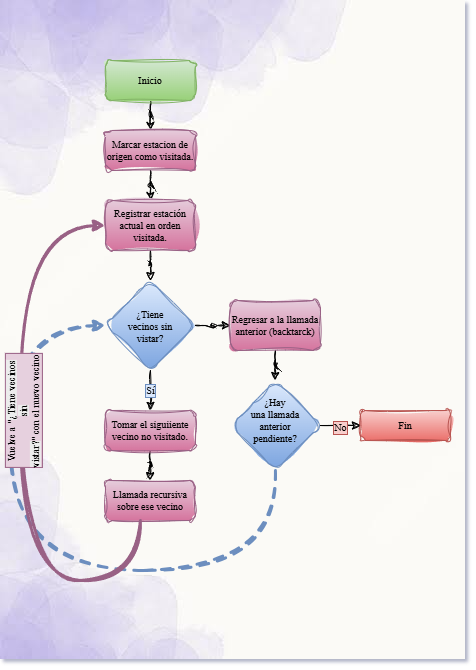
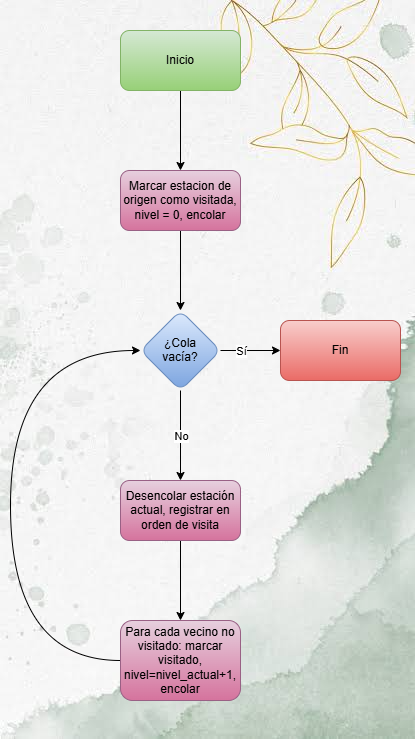

### 5) Análisis de complejidad **[15 pts]**

**Justificación:** tanto BFS como DFS visitan cada vértice una vez y revisan cada arista una vez al recorrer las listas de adyacencia.

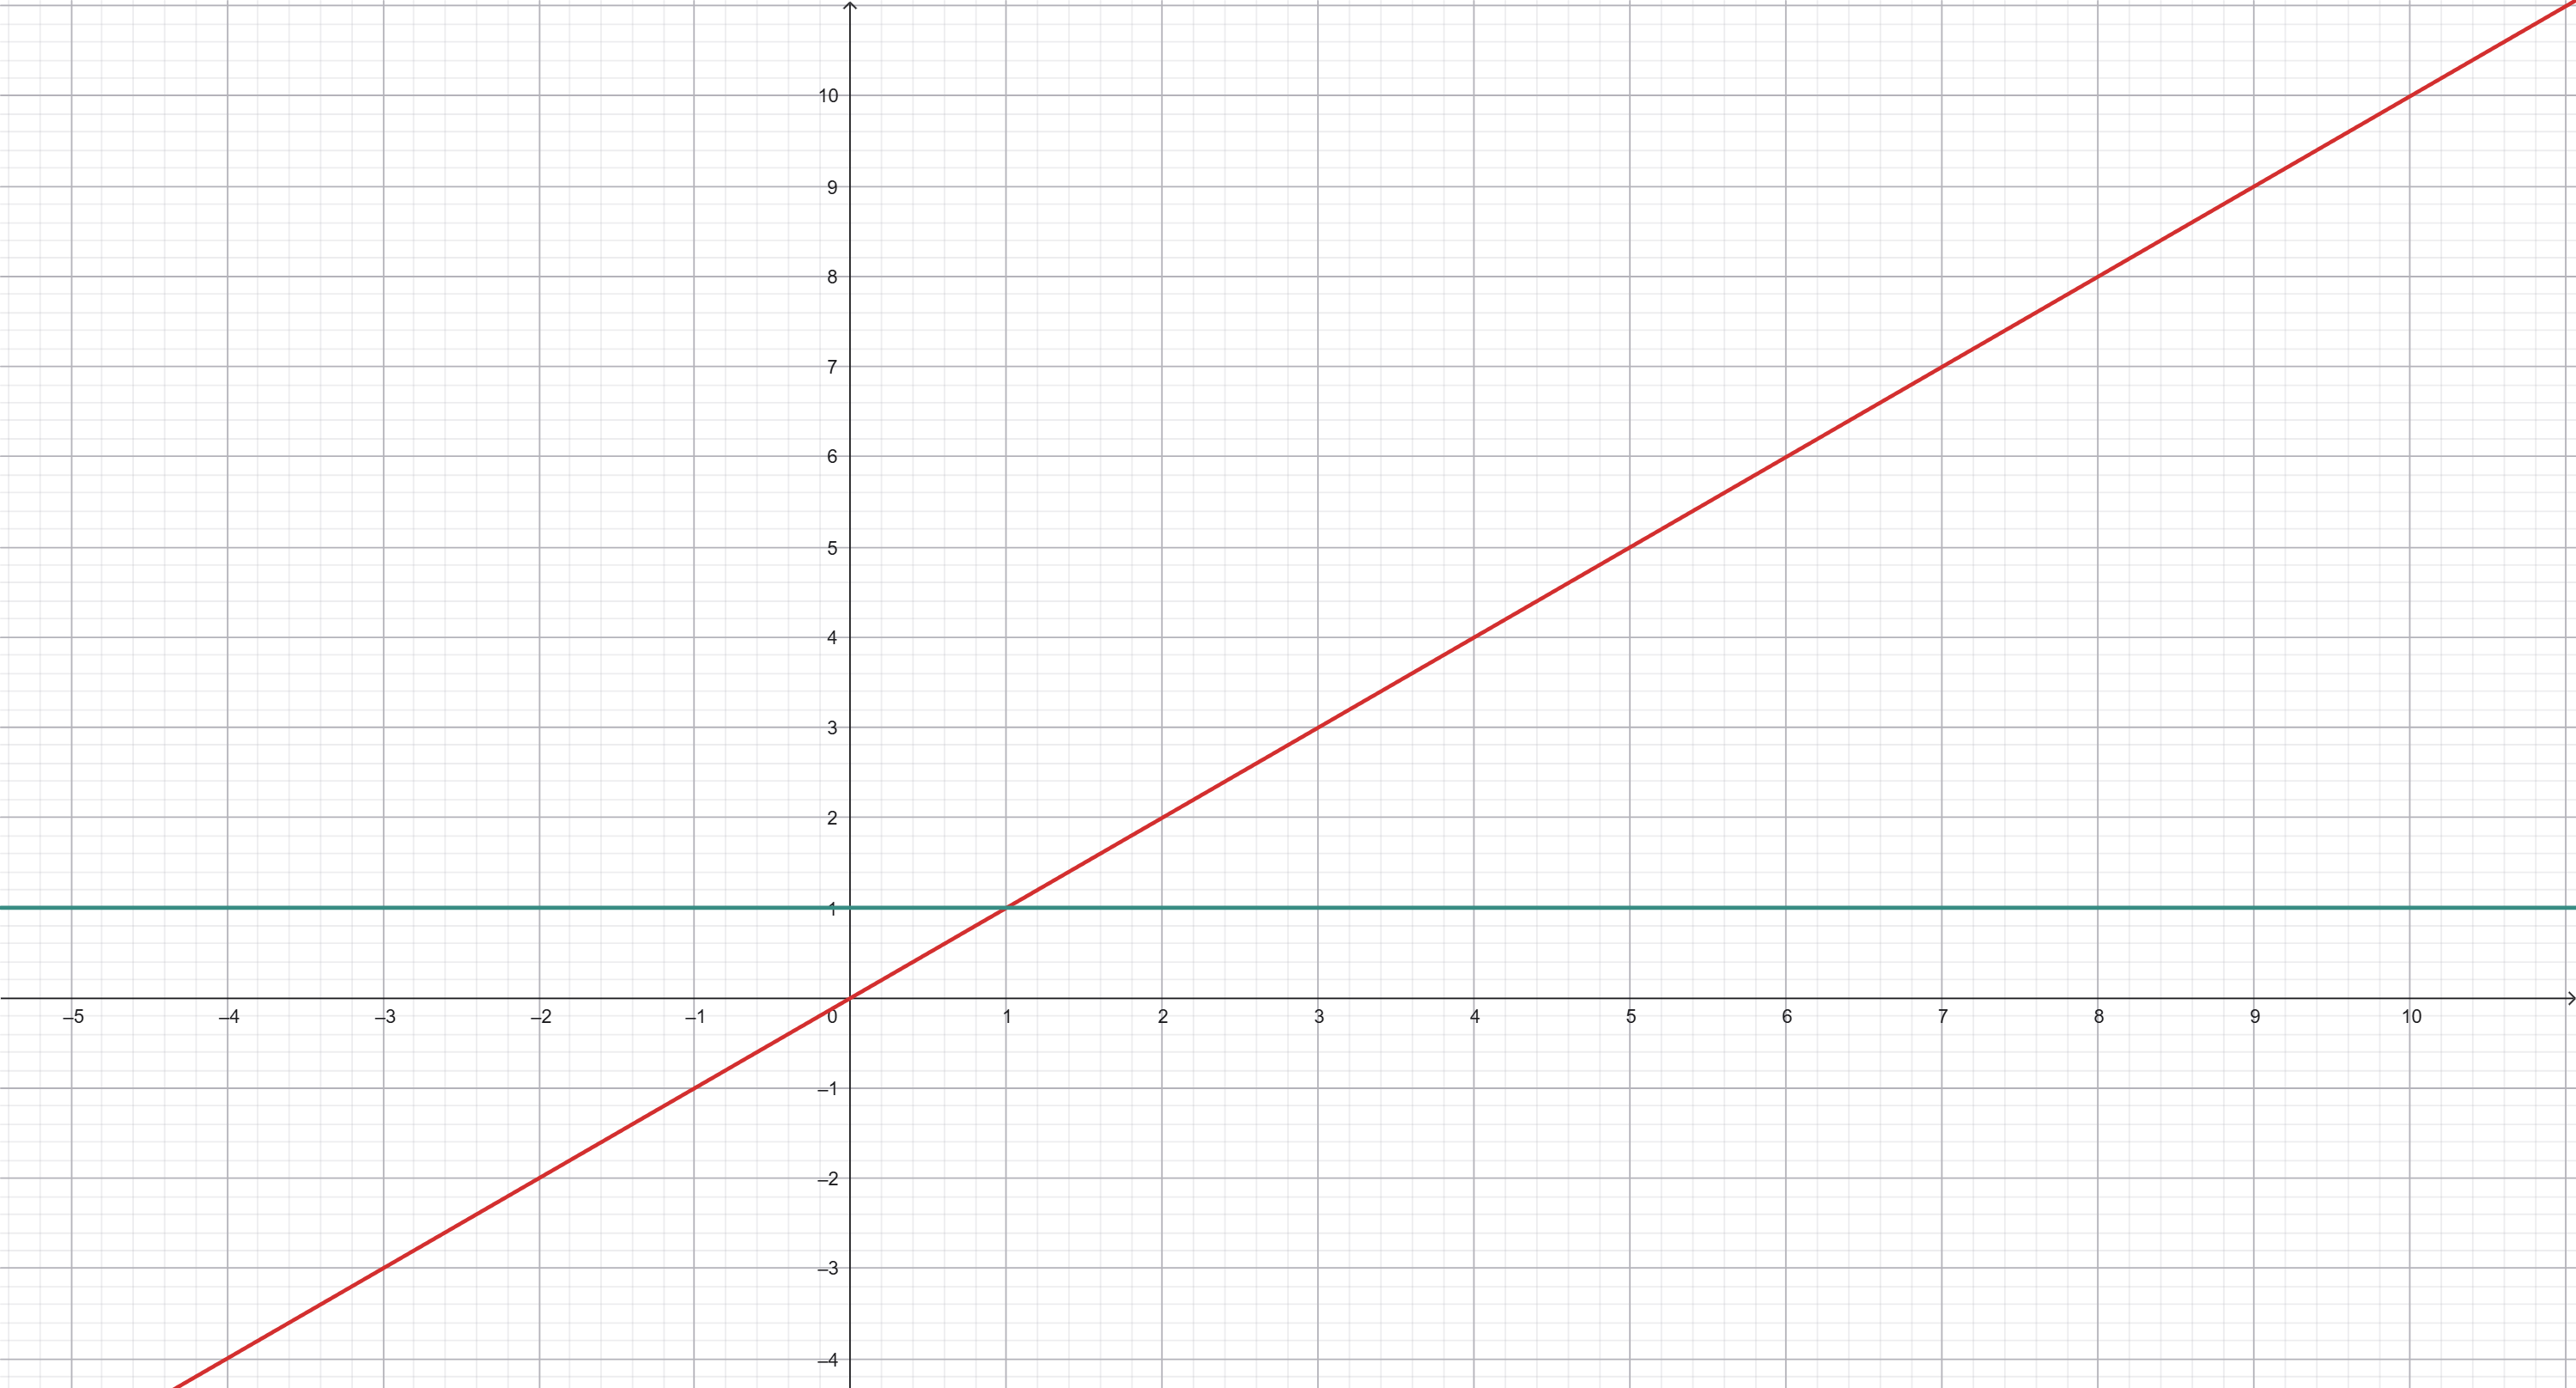

En el peor caso (ej. buscar la estación más lejana, o recorrer toda la red) el algoritmo crece linealmente con V+E. En el mejor caso (ej. el destino es un vecino directo del origen) la búsqueda termina en tiempo constante, sin depender del tamaño de la red.
 
**Función T(n):** con V estaciones y E conexiones: T(V,E) = Θ(V + E)

**Mejor caso:** el destino buscado (en el punto 5) es un vecino directo del origen → se encuentra tras revisar O(1) vértices.

**Peor caso:** hay que recorrer toda la red (todas las estaciones son alcanzables y el destino es el último en explorarse) → O(V+E).

## 6) Código funcional **[15 pts]**

In [17]:
def construir_red_inicial():
    return {
        "Central": ["Norte", "Museo"],
        "Norte": ["Central", "Parque", "Universidad"],
        "Museo": ["Central", "Hospital"],
        "Parque": ["Norte"],
        "Universidad": ["Norte", "Terminal"],
        "Hospital": ["Museo", "Terminal"],
        "Terminal": ["Universidad", "Hospital"],
    }


def mostrar_red(grafo):
    for estacion, vecinos in grafo.items():
        print(f"{estacion}: {', '.join(vecinos)}")


def existe(grafo, estacion):
    return estacion in grafo


def bfs(grafo, inicio):
    if not existe(grafo, inicio):
        return None, None
    visitados = {inicio}
    niveles = {inicio: 0}
    cola = [inicio]
    orden = []
    while cola:
        actual = cola.pop(0)
        orden.append(actual)
        for vecino in grafo.get(actual, []):
            if vecino not in visitados:
                visitados.add(vecino)
                niveles[vecino] = niveles[actual] + 1
                cola.append(vecino)
    return orden, niveles


def dfs(grafo, inicio):
    if not existe(grafo, inicio):
        return None
    visitados = set()
    orden = []
    def _rec(actual):
        visitados.add(actual)
        orden.append(actual)
        for vecino in grafo.get(actual, []):
            if vecino not in visitados:
                _rec(vecino)
    _rec(inicio)
    return orden


def bfs_ruta(grafo, inicio, destino):
    if not existe(grafo, inicio) or not existe(grafo, destino):
        return None
    if inicio == destino:
        return [inicio]
    visitados = {inicio}
    predecesores = {inicio: None}
    cola = [inicio]
    while cola:
        actual = cola.pop(0)
        for vecino in grafo.get(actual, []):
            if vecino not in visitados:
                visitados.add(vecino)
                predecesores[vecino] = actual
                if vecino == destino:
                    ruta = [destino]
                    nodo = destino
                    while predecesores[nodo] is not None:
                        nodo = predecesores[nodo]
                        ruta.append(nodo)
                    ruta.reverse()
                    return ruta
                cola.append(vecino)
    return None


def agregar_estacion(grafo, nueva, conexiones):
    grafo[nueva] = []
    for c in conexiones:
        if c not in grafo:
            continue
        if c not in grafo[nueva]:
            grafo[nueva].append(c)
        if nueva not in grafo[c]:
            grafo[c].append(nueva)
    return grafo


def niveles_agrupados(niveles):
    agrupado = {}
    for estacion, nivel in niveles.items():
        agrupado.setdefault(nivel, []).append(estacion)
    return agrupado

### Punto 1

In [18]:
red = construir_red_inicial()
mostrar_red(red)

Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal
Hospital: Museo, Terminal
Terminal: Universidad, Hospital


### Punto 2 — BFS desde Central

In [19]:
orden, niveles = bfs(red, "Central")
print("Orden BFS:", " -> ".join(orden))
for nivel, estaciones in sorted(niveles_agrupados(niveles).items()):
    print(f"Nivel {nivel}: {', '.join(estaciones)}")

Orden BFS: Central -> Norte -> Museo -> Parque -> Universidad -> Hospital -> Terminal
Nivel 0: Central
Nivel 1: Norte, Museo
Nivel 2: Parque, Universidad, Hospital
Nivel 3: Terminal


### Punto 3 — DFS desde Central

In [20]:
orden_dfs = dfs(red, "Central")
print("Orden DFS:", " -> ".join(orden_dfs))

Orden DFS: Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital -> Museo


### Punto 4 — BFS/DFS desde una estación elegida (Universidad)

In [21]:
inicio = "Universidad"
if existe(red, inicio):
    orden_b, niveles_b = bfs(red, inicio)
    orden_d = dfs(red, inicio)
    print(f"Recorrido BFS desde {inicio}:", " -> ".join(orden_b))
    for nivel, estaciones in sorted(niveles_agrupados(niveles_b).items()):
        print(f"  Nivel {nivel}: {', '.join(estaciones)}")
    print(f"Recorrido DFS desde {inicio}:", " -> ".join(orden_d))
else:
    print("La estación no existe en la red.")

Recorrido BFS desde Universidad: Universidad -> Norte -> Terminal -> Central -> Parque -> Hospital -> Museo
  Nivel 0: Universidad
  Nivel 1: Norte, Terminal
  Nivel 2: Central, Parque, Hospital
  Nivel 3: Museo
Recorrido DFS desde Universidad: Universidad -> Norte -> Central -> Museo -> Hospital -> Terminal -> Parque


### Punto 5 — Ruta Central -> Terminal

In [22]:
ruta = bfs_ruta(red, "Central", "Terminal")
if ruta is None:
    print("No existe una ruta entre las estaciones.")
else:
    print("Ruta encontrada:", " -> ".join(ruta))
    print("Cantidad de conexiones:", len(ruta) - 1)

Ruta encontrada: Central -> Norte -> Universidad -> Terminal
Cantidad de conexiones: 3


### Punto 6 — Agregar estación Aeropuerto

In [23]:
red = agregar_estacion(red, "Aeropuerto", ["Terminal", "Hospital"])
mostrar_red(red)
print()
orden2, niveles2 = bfs(red, "Central")
print("Recorrido BFS desde Central (actualizado):", " -> ".join(orden2))
for nivel, estaciones in sorted(niveles_agrupados(niveles2).items()):
    print(f"Nivel {nivel}: {', '.join(estaciones)}")
orden_dfs2 = dfs(red, "Central")
print("Recorrido DFS desde Central (actualizado):", " -> ".join(orden_dfs2))

Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal
Hospital: Museo, Terminal, Aeropuerto
Terminal: Universidad, Hospital, Aeropuerto
Aeropuerto: Terminal, Hospital

Recorrido BFS desde Central (actualizado): Central -> Norte -> Museo -> Parque -> Universidad -> Hospital -> Terminal -> Aeropuerto
Nivel 0: Central
Nivel 1: Norte, Museo
Nivel 2: Parque, Universidad, Hospital
Nivel 3: Terminal, Aeropuerto
Recorrido DFS desde Central (actualizado): Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital -> Museo -> Aeropuerto


## 7) Tests aplicados **[15 pts]**

In [24]:
def test(obtenido, esperado):
    assert obtenido == esperado, f"se obtuvo {obtenido}, se esperaba {esperado}"
    print(f"OK: {obtenido}")
 
 
orden, niveles = bfs(red, "Central")
test(orden[:7], ["Central","Norte","Museo","Parque","Universidad","Hospital","Terminal"])
test(niveles["Central"], 0)
test(niveles["Terminal"], 3)
 
test(dfs(red, "Central")[:7], ["Central","Norte","Parque","Universidad","Terminal","Hospital","Museo"])
 
 
test(bfs_ruta(red, "Central", "Terminal"), ["Central","Norte","Universidad","Terminal"])
 
 
test(bfs(red, "NoExiste"), (None, None))
test(bfs_ruta(red, "Central", "NoExiste"), None)
 

OK: ['Central', 'Norte', 'Museo', 'Parque', 'Universidad', 'Hospital', 'Terminal']
OK: 0
OK: 3
OK: ['Central', 'Norte', 'Parque', 'Universidad', 'Terminal', 'Hospital', 'Museo']
OK: ['Central', 'Norte', 'Universidad', 'Terminal']
OK: (None, None)
OK: None
